# Phát hiện Deepfake qua VIDEO — Machine Learning (2 cách)

Notebook xử lý **video DFDC part 15** (`data-raw/data/dfdc_train_part_15`): các file `.mp4` nằm chung 1 thư mục, **nhãn REAL/FAKE nằm trong `metadata.json`** (không chia sẵn thư mục).

Dùng **model ảnh tốt nhất đã train ở notebook ML ảnh** (`best_model.pkl`, upload lên Kaggle làm input) và kèm thêm một cách nữa:

| | Cách | Ý tưởng |
|---|---|---|
| **A** | Dùng thẳng `best_model.pkl` | Lấy ~16 khung hình rải đều → dò + cắt mặt → trích đặc trưng (LBP, HOG, FFT, màu) → model ảnh cho **P(Fake) từng khung** → kết luận video bằng **trung bình xác suất** hoặc **bỏ phiếu** |
| **B** | Train model ML mới ở **mức video** | Gộp đặc trưng các khung hình thành **1 vector/video** (mean/std/min/max + thống kê P(Fake) + đặc trưng thời gian) → huấn luyện 7 thuật toán ML trên video |

**Chia train/test theo video gốc** (`original` trong metadata): video Real gốc và các bản Fake của nó luôn nằm cùng 1 phía → không rò rỉ dữ liệu. Giữ riêng **5 video làm demo**.

**Quy trình:** 0. Tìm dữ liệu + nạp model → 1. Hàm xử lý khung hình/đặc trưng → 2. Đọc `metadata.json` → 3. Build dataset cấp video (chạy song song) → 4. Bảng đặc trưng tiếng Việt → 5. Đánh giá A vs B (cùng tập test) → 6. Demo 5 video.

> **Chuẩn bị:** (1) Add Data `data-raw` (có `dfdc_train_part_15`); (2) Add Data chứa file `best_model.pkl` (output của notebook ML ảnh). **Không cần GPU.**

## 0. Cài đặt, tìm dữ liệu và nạp model ảnh

In [1]:
# Dùng cùng phiên bản scikit-learn với notebook ML ảnh (để nạp best_model.pkl không lỗi). Cần bật Internet; nếu notebook ML ảnh KHÔNG chạy lệnh này thì xóa dòng dưới.
!pip install -q -U scikit-learn

In [2]:
import os, glob, json, random, shutil, time, warnings
import numpy as np
import pandas as pd
import cv2
import joblib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
%matplotlib inline

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
# ---- Có thể gán tay nếu tự tìm không ra ----
# DFDC_SRC   = "/kaggle/input/datasets/whissnguyen/data-raw/data/dfdc_train_part_15"
# MODEL_PATH = "/kaggle/input/<tên-dataset-chứa-model>/best_model.pkl"
DFDC_SRC = globals().get("DFDC_SRC")
MODEL_PATH = globals().get("MODEL_PATH")

# ---- 1) Thư mục video DFDC part 15 (chứa metadata.json + .mp4) ----
if DFDC_SRC is None:
    for base in ("/kaggle/input/datasets/whissnguyen/data-raw/data", "/kaggle/input/data-raw/data"):
        if os.path.isfile(os.path.join(base, "dfdc_train_part_15", "metadata.json")):
            DFDC_SRC = os.path.join(base, "dfdc_train_part_15")
            break
if DFDC_SRC is None:                       # tự dò, bỏ qua thư mục ảnh 'Dataset' (hàng trăm nghìn file)
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count("/") - 2 > 6:
            dirs.clear(); continue
        dirs[:] = [d for d in dirs if d != "Dataset"]
        if "metadata.json" in files and "dfdc" in root.lower():
            DFDC_SRC = root
            break
if DFDC_SRC is None:
    raise FileNotFoundError("Không thấy dfdc_train_part_15/metadata.json - kiểm tra Add Data 'data-raw' hoặc gán tay DFDC_SRC.")

# ---- 2) File best_model.pkl (từ notebook ML ảnh) ----
if MODEL_PATH is None:
    pats = ["/kaggle/input/*/best_model*.pkl", "/kaggle/input/*/*/best_model*.pkl", "/kaggle/input/*/*/*/best_model*.pkl",
            "/kaggle/input/datasets/*/*/best_model*.pkl", "/kaggle/input/datasets/*/*/*/best_model*.pkl",
            "/kaggle/input/datasets/*/*/*/*/best_model*.pkl"]
    hits = [p for pat in pats for p in glob.glob(pat)]
    if hits:
        MODEL_PATH = sorted(hits, key=len)[0]
if MODEL_PATH is None:
    raise FileNotFoundError("Không thấy best_model.pkl - hãy upload file thành 1 Kaggle Dataset rồi Add Data, hoặc gán tay MODEL_PATH.")

print("DFDC_SRC  :", DFDC_SRC, "| số .mp4:", len(glob.glob(os.path.join(DFDC_SRC, "*.mp4"))))
print("MODEL_PATH:", MODEL_PATH)

DFDC_SRC  : /kaggle/input/datasets/trnganv/data-raw/data/dfdc_train_part_15 | số .mp4: 2273
MODEL_PATH: /kaggle/input/datasets/whissnguyen/best-model/best_model.pkl


### 0.1 Hàm cắt mặt và trích đặc trưng ảnh (GIỐNG HỆT notebook ML ảnh để khớp với `best_model.pkl`)

In [4]:
IMG_SIZE = 128  # phải khớp notebook ML ảnh

In [5]:
VALID_EXTS = (".jpg", ".jpeg", ".png")
CLASSES = ("Real", "Fake")

# --------------------------------------------------------------------- #
# 1) FACE DETECTION + CROP
# --------------------------------------------------------------------- #
_FACE_CASCADE = None


def get_face_detector() -> cv2.CascadeClassifier:
    """Load Haar Cascade face detector 1 lần duy nhất (cache)."""
    global _FACE_CASCADE
    if _FACE_CASCADE is None:
        cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
        _FACE_CASCADE = cv2.CascadeClassifier(cascade_path)
    return _FACE_CASCADE


def detect_and_crop_face(bgr_img: np.ndarray, margin: float = 0.3):
    """
    Phát hiện khuôn mặt lớn nhất trong ảnh và crop kèm margin xung quanh.
    Trả về (cropped_img, found_face: bool). Nếu không tìm thấy mặt, trả về
    ảnh gốc (giả định đã crop sẵn) kèm found_face=False.
    """
    detector = get_face_detector()
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    faces = detector.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40)
    )

    if len(faces) == 0:
        return bgr_img, False

    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

    mx, my = int(w * margin), int(h * margin)
    h_img, w_img = bgr_img.shape[:2]
    x0 = max(0, x - mx)
    y0 = max(0, y - my)
    x1 = min(w_img, x + w + mx)
    y1 = min(h_img, y + h + my)

    cropped = bgr_img[y0:y1, x0:x1]
    if cropped.size == 0:
        return bgr_img, False
    return cropped, True

In [6]:
from skimage.feature import local_binary_pattern, hog

LBP_RADIUS = 2
LBP_POINTS = 8 * LBP_RADIUS


def extract_lbp(gray_img: np.ndarray) -> np.ndarray:
    """Trả về histogram LBP đã chuẩn hóa (uniform pattern)."""
    lbp = local_binary_pattern(gray_img, LBP_POINTS, LBP_RADIUS, method="uniform")
    n_bins = LBP_POINTS + 2
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins))
    hist = hist.astype("float32")
    hist /= (hist.sum() + 1e-7)
    return hist


def extract_hog(gray_img: np.ndarray) -> np.ndarray:
    """Trả về vector đặc trưng HOG."""
    features = hog(
        gray_img, orientations=9, pixels_per_cell=(16, 16),
        cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True,
    )
    return features.astype("float32")


def extract_fft_features(gray_img: np.ndarray) -> np.ndarray:
    """
    Trích đặc trưng miền tần số bằng FFT 2D. Deepfake (đặc biệt ảnh GAN)
    thường để lại năng lượng bất thường ở dải tần số cao. Chia phổ tần số
    thành các dải vòng (radial bins) và lấy năng lượng trung bình mỗi dải.
    """
    f = np.fft.fft2(gray_img)
    fshift = np.fft.fftshift(f)
    magnitude = np.log1p(np.abs(fshift))

    h, w = magnitude.shape
    cy, cx = h // 2, w // 2
    y, x = np.indices((h, w))
    r = np.sqrt((x - cx) ** 2 + (y - cy) ** 2).astype(int)

    n_bins = 16
    max_r = r.max()
    bin_edges = np.linspace(0, max_r, n_bins + 1)
    radial_features = []
    for i in range(n_bins):
        mask = (r >= bin_edges[i]) & (r < bin_edges[i + 1])
        if mask.sum() > 0:
            radial_features.append(magnitude[mask].mean())
        else:
            radial_features.append(0.0)

    radial_features = np.array(radial_features, dtype="float32")
    low = radial_features[: n_bins // 3].sum() + 1e-7
    high = radial_features[2 * n_bins // 3 :].sum()
    ratio = np.array([high / low], dtype="float32")

    return np.concatenate([radial_features, ratio])


def extract_color_histogram(bgr_img: np.ndarray) -> np.ndarray:
    """Histogram màu trong không gian HSV (bắt lệch tông da khi ghép mặt)."""
    hsv = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
    hist = cv2.normalize(hist, hist).flatten()
    return hist.astype("float32")


def extract_features(bgr_img: np.ndarray) -> np.ndarray:
    """Ghép toàn bộ đặc trưng thành 1 vector duy nhất cho 1 ảnh."""
    bgr_img = cv2.resize(bgr_img, (IMG_SIZE, IMG_SIZE))
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)

    lbp_feat = extract_lbp(gray)
    hog_feat = extract_hog(gray)
    fft_feat = extract_fft_features(gray)
    color_feat = extract_color_histogram(bgr_img)

    return np.concatenate([lbp_feat, hog_feat, fft_feat, color_feat])

In [7]:
# ===================== NẠP MODEL ẢNH TỐT NHẤT =====================
bundle = joblib.load(MODEL_PATH)
img_model, img_scaler, img_model_name = bundle["model"], bundle["scaler"], bundle["model_name"]
n_feat = len(extract_features(np.zeros((IMG_SIZE, IMG_SIZE, 3), np.uint8)))
print(f"Model ảnh: {img_model_name} | số đặc trưng model cần: {img_scaler.n_features_in_} | notebook này tạo: {n_feat}")
assert img_scaler.n_features_in_ == n_feat, "Số đặc trưng không khớp - IMG_SIZE/hàm trích đặc trưng phải giống notebook ML ảnh."

Model ảnh: SVM_RBF | số đặc trưng model cần: 2311 | notebook này tạo: 2311


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
)


def get_models() -> dict:
    # class_weight="balanced" giúp model không thiên vị lớp đa số, đóng vai
    # trò lớp bảo hiểm thứ 2 bên cạnh bước cân bằng lớp bằng augmentation ở
    # Bước 1 (phòng khi dữ liệu vẫn còn lệch nhẹ sau bước đó). KNN,
    # NaiveBayes, GradientBoosting (bản sklearn) không hỗ trợ tham số này.
    return {
        "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "KNN": KNeighborsClassifier(n_neighbors=7),
        "NaiveBayes": GaussianNB(),
        "DecisionTree": DecisionTreeClassifier(max_depth=12, random_state=42, class_weight="balanced"),
        "RandomForest": RandomForestClassifier(
            n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced"
        ),
        "SVM_RBF": SVC(kernel="rbf", C=2.0, probability=True, random_state=42, class_weight="balanced"),
        "GradientBoosting": GradientBoostingClassifier(random_state=42),
    }


def evaluate_model(model, X_test, y_test) -> dict:
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = y_pred

    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "auc": roc_auc_score(y_test, y_score),
        "y_pred": y_pred,
    }


def plot_confusion_matrix(y_test, y_pred, model_name: str, out_dir: str):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xticks([0, 1], ["Fake", "Real"])
    plt.yticks([0, 1], ["Fake", "Real"])
    plt.xlabel("Dự đoán")
    plt.ylabel("Thực tế")
    for i in range(2):
        for j in range(2):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                      color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"cm_{model_name}.png"), dpi=150)
    plt.show()


def plot_comparison_chart(results_df: pd.DataFrame, out_dir: str):
    metrics = ["accuracy", "precision", "recall", "f1", "auc"]
    x = np.arange(len(results_df))
    width = 0.15

    plt.figure(figsize=(11, 6))
    for i, m in enumerate(metrics):
        plt.bar(x + i * width, results_df[m], width, label=m)

    plt.xticks(x + width * 2, results_df["model"], rotation=20)
    plt.ylabel("Điểm số")
    plt.title("So sánh các thuật toán Machine Learning")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "model_comparison.png"), dpi=150)
    plt.show()

In [9]:
# ===================== CẤU HÌNH PHẦN VIDEO =====================
VIDEO_EXTS = (".mp4", ".avi", ".mov", ".mkv", ".webm")
N_FRAMES = 16                    # số khung hình lấy mẫu rải đều cho mỗi video
THRESHOLD = 0.5                  # ngưỡng P(Fake)
MAX_SIDE = 640                   # thu nhỏ khung hình (cạnh dài tối đa) trước khi dò mặt cho nhanh
MAX_VIDEOS_PER_CLASS = None      # None = dùng TOÀN BỘ video; đặt số nhỏ (vd 60) để chạy thử nhanh
N_DEMO_REAL, N_DEMO_FAKE = 2, 3  # bộ video demo, giữ ngoài tập học
# --- Kiểm tra chất lượng khuôn mặt (trạng thái video: OK / NO_FACE / INSUFFICIENT_QUALITY) ---
MIN_FACE_PX = 56                 # cạnh nhỏ nhất của khung mặt (pixel, sau khi thu nhỏ về MAX_SIDE); nhỏ hơn = "mặt quá nhỏ"
BLUR_THRESHOLD = 25.0            # phương sai Laplacian của vùng mặt (resize 128x128); thấp hơn = "mặt quá mờ". Chỉnh theo dữ liệu (xem video_status.csv)
MIN_GOOD_FRAMES = 3              # cần ít nhất ngần này khung mặt đạt chất lượng, nếu không -> INSUFFICIENT_QUALITY
N_JOBS = -1                      # chạy song song bằng tất cả CPU
REUSE_CACHE = True               # True: nếu đã build xong trước đó thì nạp lại (xóa outputs/video_features.csv để build lại)

VIDEO_MODEL_PATH = os.path.join(OUTPUT_DIR, "best_video_model.pkl")
VIDEO_FEATURES_CSV = os.path.join(OUTPUT_DIR, "video_features.csv")

## 1. Hàm xử lý video

- `extract_video`: lấy 16 khung hình rải đều → dò + cắt mặt → **kiểm tra chất lượng mặt** (kích thước `MIN_FACE_PX`, độ mờ = phương sai Laplacian `BLUR_THRESHOLD`) → đặc trưng từng khung. Hàm này **không cần model** nên chạy song song được. Trạng thái video:
  - `NO_FACE`: không thấy mặt ở **cả 16 khung**;
  - `INSUFFICIENT_QUALITY`: có thấy mặt nhưng mặt quá nhỏ hoặc quá mờ (ít hơn `MIN_GOOD_FRAMES` khung đạt chuẩn);
  - `OK`: đủ khung tốt → mới dự đoán Real/Fake. (Bỏ fallback cũ "dùng toàn bộ khung khi không thấy mặt" vì sẽ cho kết quả không đáng tin.)
- `frame_p_fake`: dùng `best_model.pkl` để ra **P(Fake) từng khung** (Cách A).
- `video_feature_vector`: gộp các khung thành **1 vector đặc trưng cấp video** (Cách B).

In [10]:
def sample_video_frames(video_path: str, n_frames: int = N_FRAMES):
    """Lấy tối đa n_frames khung hình rải đều (không lấy hết vì các khung liên tiếp gần như giống nhau)."""
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        raise RuntimeError(f"Không đọc được video (thiếu codec hoặc file lỗi): {video_path}")
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    ids = np.linspace(0, total - 1, min(n_frames, total), dtype=int)

    frames, kept_ids = [], []
    for fid in ids:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(fid))
        ok, frame = cap.read()
        if ok:
            h, w = frame.shape[:2]
            if max(h, w) > MAX_SIDE:
                s = MAX_SIDE / max(h, w)
                frame = cv2.resize(frame, (int(w * s), int(h * s)))
            frames.append(frame)
            kept_ids.append(int(fid))
    cap.release()
    if not frames:
        raise RuntimeError(f"Không trích được khung hình nào từ video: {video_path}")
    return frames, kept_ids, fps


def assess_face_quality(frame: np.ndarray, margin: float = 0.3) -> dict:
    """Dò mặt lớn nhất trong 1 khung và chấm chất lượng.
    status: 'no_face' (không thấy mặt) | 'too_small' (mặt < MIN_FACE_PX) | 'blurry' (phương sai Laplacian < BLUR_THRESHOLD) | 'ok'."""
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = get_face_detector().detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    if len(faces) == 0:
        return {"status": "no_face"}
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
    face_px = int(min(w, h))
    face_gray = cv2.resize(gray[y:y + h, x:x + w], (IMG_SIZE, IMG_SIZE))        # cùng kích thước -> độ mờ so sánh được
    blur = float(cv2.Laplacian(face_gray, cv2.CV_64F).var())
    h_img, w_img = frame.shape[:2]
    mx, my = int(w * margin), int(h * margin)
    crop = frame[max(0, y - my):min(h_img, y + h + my), max(0, x - mx):min(w_img, x + w + mx)]
    if crop.size == 0:
        return {"status": "no_face"}
    status = "too_small" if face_px < MIN_FACE_PX else ("blurry" if blur < BLUR_THRESHOLD else "ok")
    return {"status": status, "crop": crop, "face_px": face_px, "blur": blur}


def extract_video(video_path: str, n_frames: int = N_FRAMES, keep_crops: bool = False) -> dict:
    """Đặc trưng từng khung của 1 video (không cần model).
    Luôn có: status, n_frames, n_no_face, n_too_small, n_blurry, n_good, face_px_median, blur_median.
    status = 'NO_FACE'              : không thấy mặt ở TẤT CẢ các khung đã lấy mẫu (vd 16/16)
           = 'INSUFFICIENT_QUALITY' : có thấy mặt nhưng < MIN_GOOD_FRAMES khung đạt chuẩn (mặt quá nhỏ hoặc quá mờ)
           = 'OK'                   : có thêm feats, pix_diff, frame_ids, fps[, crops]."""
    cv2.setNumThreads(1)
    frames, frame_ids, fps = sample_video_frames(video_path, n_frames)
    crops, feats, used = [], [], []
    cnt = {"no_face": 0, "too_small": 0, "blurry": 0, "ok": 0}
    sizes, blurs = [], []
    for fr, fid in zip(frames, frame_ids):
        q = assess_face_quality(fr)
        cnt[q["status"]] += 1
        if q["status"] == "no_face":
            continue
        sizes.append(q["face_px"]); blurs.append(q["blur"])
        if q["status"] != "ok":                      # mặt quá nhỏ / quá mờ -> không dùng khung này
            continue
        crops.append(cv2.resize(q["crop"], (IMG_SIZE, IMG_SIZE)))
        feats.append(extract_features(q["crop"]))
        used.append(fid)

    out = {"n_frames": len(frames), "n_no_face": cnt["no_face"], "n_too_small": cnt["too_small"],
           "n_blurry": cnt["blurry"], "n_good": cnt["ok"],
           "face_px_median": float(np.median(sizes)) if sizes else float("nan"),
           "blur_median": float(np.median(blurs)) if blurs else float("nan")}
    if cnt["no_face"] == len(frames):
        out["status"] = "NO_FACE"
        return out
    if cnt["ok"] < MIN_GOOD_FRAMES:
        out["status"] = "INSUFFICIENT_QUALITY"
        return out

    gray = [cv2.resize(cv2.cvtColor(c, cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32) for c in crops]
    pix_diff = np.array([np.abs(gray[i + 1] - gray[i]).mean() for i in range(len(gray) - 1)], np.float32)
    out.update({"status": "OK", "feats": np.vstack(feats).astype(np.float32), "pix_diff": pix_diff,
                "frame_ids": used, "fps": fps})
    if keep_crops:
        out["crops"] = crops
    return out


def frame_p_fake(feats: np.ndarray, model=None, scaler=None) -> np.ndarray:
    """P(Fake) của từng khung theo model ảnh (nhãn 1 = Real, 0 = Fake)."""
    model, scaler = model or img_model, scaler or img_scaler
    X = scaler.transform(feats)
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, list(model.classes_).index(0)]
    if hasattr(model, "decision_function"):            # vd LinearSVC: điểm > 0 ứng với Real
        return 1.0 / (1.0 + np.exp(model.decision_function(X)))
    return (model.predict(X) == 0).astype(float)


def aggregate_video_a(p_fake: np.ndarray, thr: float = THRESHOLD) -> dict:
    """Cách A: tổng hợp xác suất từng khung thành kết luận cho cả video."""
    mean_p = float(np.mean(p_fake))
    frac_fake = float(np.mean(p_fake >= thr))
    return {"mean_p_fake": mean_p, "frac_fake_frames": frac_fake,
            "pred_mean": "Fake" if mean_p >= thr else "Real", "pred_vote": "Fake" if frac_fake > 0.5 else "Real"}


def _lowdim_feature_idx() -> np.ndarray:
    """Chỉ số các cột LBP + FFT trong vector đặc trưng (bỏ HOG & Color Histogram: quá nhiều chiều)."""
    g = np.zeros((IMG_SIZE, IMG_SIZE), np.uint8)
    n_lbp, n_hog, n_fft = len(extract_lbp(g)), len(extract_hog(g)), len(extract_fft_features(g))
    return np.concatenate([np.arange(0, n_lbp), np.arange(n_lbp + n_hog, n_lbp + n_hog + n_fft)])

LOWDIM_IDX = _lowdim_feature_idx()


def video_feature_vector(feats: np.ndarray, pix_diff: np.ndarray, p: np.ndarray) -> np.ndarray:
    """Cách B: 1 vector/video = thống kê LBP+FFT (mean/std/min/max) + thống kê P(Fake) + đặc trưng thời gian (151 chiều)."""
    F_ = feats[:, LOWDIM_IDX]
    agg = np.concatenate([F_.mean(0), F_.std(0), F_.min(0), F_.max(0)])
    p_stats = np.array([p.mean(), p.std(), p.min(), p.max(), np.median(p), (p >= THRESHOLD).mean()])
    if len(p) > 1:
        feat_diff = np.linalg.norm(np.diff(F_, axis=0), axis=1)
        temporal = np.array([pix_diff.mean(), pix_diff.std(), feat_diff.mean(), feat_diff.std(), np.abs(np.diff(p)).mean()])
    else:
        temporal = np.zeros(5)
    return np.concatenate([agg, p_stats, temporal]).astype("float32")

## 2. Đọc `metadata.json` (nhãn) và chia nhóm theo video gốc

`metadata.json` có dạng `{"tên.mp4": {"label": "REAL"/"FAKE", "original": "video_gốc.mp4"}}`. Từ đó:
- nhãn: `REAL` → 1, `FAKE` → 0;
- `group` = video gốc (video Real tự là nhóm của nó; bản Fake thuộc nhóm của video gốc) → dùng để chia train/test không rò rỉ;
- chọn vài nhóm làm **video demo** và loại **cả nhóm** khỏi tập học.

metadata.json: 2273 mục | có file: 2273 | REAL=398 | FAKE=1875
Dùng để học/đánh giá: 2232 video | Real=393 | Fake=1839 | số nhóm (video gốc): 393
Video demo (loại khỏi tập học): ['cbkppzjtqf.mp4', 'cwaoshhenk.mp4', 'tqhthygumd.mp4', 'gyeaqcnxhx.mp4', 'mfsoyljskv.mp4']


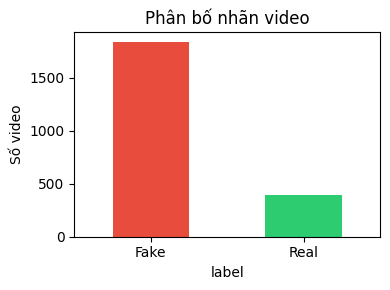

In [11]:
with open(os.path.join(DFDC_SRC, "metadata.json"), "r", encoding="utf-8") as f:
    meta = json.load(f)

present = {n: m for n, m in meta.items() if os.path.exists(os.path.join(DFDC_SRC, n))}   # chỉ giữ video thực sự có file
n_real_all = sum(m["label"] == "REAL" for m in present.values())
print(f"metadata.json: {len(meta)} mục | có file: {len(present)} | REAL={n_real_all} | FAKE={len(present) - n_real_all}")

# --- chọn video demo: vài video gốc Real + bản Fake của video gốc khác; loại cả nhóm khỏi tập học ---
random.seed(42)
children = {}
for n, m in present.items():
    if m["label"] == "FAKE" and m.get("original") in present:
        children.setdefault(m["original"], []).append(n)
cand = list(children)
random.shuffle(cand)
demo_orig = cand[:N_DEMO_REAL + N_DEMO_FAKE]
demo_real = demo_orig[:N_DEMO_REAL]
demo_fake = [random.choice(children[o]) for o in demo_orig[N_DEMO_REAL:]]
held_out = set(demo_orig) | {n for o in demo_orig for n in children[o]}
demo_files = demo_real + demo_fake
demo_truth = {n: ("Real" if present[n]["label"] == "REAL" else "Fake") for n in demo_files}

rows = []
for n, m in present.items():
    if n in held_out:
        continue
    is_real = m["label"] == "REAL"
    rows.append({"path": os.path.join(DFDC_SRC, n), "file": n, "label": int(is_real),
                 "group": n if is_real else (m.get("original") or n)})
video_list_df = pd.DataFrame(rows)

print(f"Dùng để học/đánh giá: {len(video_list_df)} video | Real={int((video_list_df.label == 1).sum())} | Fake={int((video_list_df.label == 0).sum())}"
      f" | số nhóm (video gốc): {video_list_df['group'].nunique()}")
print("Video demo (loại khỏi tập học):", demo_files)

video_list_df["label"].map({1: "Real", 0: "Fake"}).value_counts().plot(kind="bar", color=["#e74c3c", "#2ecc71"], rot=0, figsize=(4, 3))
plt.title("Phân bố nhãn video"); plt.ylabel("Số video"); plt.tight_layout(); plt.show()

## 3. Build dataset cấp video (chạy song song)

Mỗi video: đọc 16 khung hình → dò mặt → trích đặc trưng (song song nhiều CPU) → `best_model.pkl` cho P(Fake) từng khung (**Cách A**) → vector đặc trưng cấp video (**Cách B**).
Với hơn 2000 video bước này mất khoảng **15–40 phút** (có thanh tiến trình). Video `NO_FACE` / `INSUFFICIENT_QUALITY` bị loại khỏi tập học và ghi vào `outputs/video_status.csv` (kèm số khung, kích thước mặt, độ mờ để chỉnh ngưỡng). Kết quả lưu cache `outputs/video_features.csv` nên lần sau nạp lại ngay.

In [12]:
def _safe_extract(path):
    try:
        return extract_video(path)
    except Exception as e:
        return {"error": str(e)}


def build_video_dataset(video_df: pd.DataFrame, max_per_class=MAX_VIDEOS_PER_CLASS, seed: int = 42, out_csv: str = VIDEO_FEATURES_CSV) -> pd.DataFrame:
    parts = []
    for label_val in (1, 0):
        sub = video_df[video_df["label"] == label_val]
        if max_per_class is not None and len(sub) > max_per_class:
            sub = sub.sample(max_per_class, random_state=seed)
        parts.append(sub)
    chosen = pd.concat(parts).reset_index(drop=True)
    print(f"[INFO] Dùng {len(chosen)} video (Real={int((chosen.label == 1).sum())}, Fake={int((chosen.label == 0).sum())})")

    paths = chosen["path"].tolist()
    try:
        gen = Parallel(n_jobs=N_JOBS, return_as="generator")(delayed(_safe_extract)(p) for p in paths)
        results = list(tqdm(gen, total=len(paths), desc="Trích đặc trưng video"))
    except TypeError:                                                  # joblib cũ không có return_as
        results = Parallel(n_jobs=N_JOBS)(delayed(_safe_extract)(p) for p in tqdm(paths, desc="Trích đặc trưng video"))

    rows, status_rows = [], []
    for (_, r), info in zip(chosen.iterrows(), results):
        if "error" in info:
            print(f"[WARN] Bỏ qua {r['file']}: {info['error']}")
            status_rows.append({"file": r["file"], "status": "ERROR", "error": info["error"]})
            continue
        status_rows.append({"file": r["file"], "label": r["label"], **{k: v for k, v in info.items() if not isinstance(v, (np.ndarray, list))}})
        if info["status"] != "OK":                                     # NO_FACE / INSUFFICIENT_QUALITY: không đưa vào tập học
            continue
        p = frame_p_fake(info["feats"])                                # Cách A: P(Fake) từng khung theo best_model.pkl
        agg = aggregate_video_a(p)
        vec = video_feature_vector(info["feats"], info["pix_diff"], p) # Cách B: vector cấp video
        row = {"file": r["file"], "label": r["label"], "group": r["group"],
               "n_good_frames": info["n_good"],
               "mean_p_fake": agg["mean_p_fake"], "frac_fake_frames": agg["frac_fake_frames"]}
        row.update({f"vf_{i}": v for i, v in enumerate(vec)})
        rows.append(row)

    if not rows:
        raise RuntimeError("Không trích được đặc trưng của video nào.")
    status_df = pd.DataFrame(status_rows)
    status_df.to_csv(os.path.join(OUTPUT_DIR, "video_status.csv"), index=False, encoding="utf-8-sig")
    print("[INFO] Trạng thái video:", status_df["status"].value_counts().to_dict(),
          f"(MIN_FACE_PX={MIN_FACE_PX}, BLUR_THRESHOLD={BLUR_THRESHOLD}, MIN_GOOD_FRAMES={MIN_GOOD_FRAMES})")
    df = pd.DataFrame(rows)
    df.to_csv(out_csv, index=False)
    print(f"[OK] Đã lưu {len(df)} video -> {out_csv}")
    return df


_cached = pd.read_csv(VIDEO_FEATURES_CSV) if (REUSE_CACHE and os.path.exists(VIDEO_FEATURES_CSV)) else None
if _cached is not None and "n_good_frames" in _cached.columns and len(_cached) >= 0.9 * min(len(video_list_df), 2 * (MAX_VIDEOS_PER_CLASS or 10**9)):
    video_feat_df = _cached
    print(f"[INFO] Nạp lại cache: {len(video_feat_df)} video")
else:
    video_feat_df = build_video_dataset(video_list_df)
video_feat_df.iloc[:5, :8]

[INFO] Dùng 2232 video (Real=393, Fake=1839)


Trích đặc trưng video:   0%|          | 0/2232 [00:00<?, ?it/s]

[INFO] Trạng thái video: {'OK': 1205, 'INSUFFICIENT_QUALITY': 833, 'NO_FACE': 194} (MIN_FACE_PX=56, BLUR_THRESHOLD=25.0, MIN_GOOD_FRAMES=3)
[OK] Đã lưu 1205 video -> outputs/video_features.csv


,file,label,group,n_good_frames,mean_p_fake,frac_fake_frames,vf_0,vf_1
0,vuikiiwjvt.mp4,1,vuikiiwjvt.mp4,16,0.298217,0.125000,0.019176,0.016533
1,yilhaiiopo.mp4,1,yilhaiiopo.mp4,16,0.232974,0.250000,0.024227,0.027615
2,lacuurfajw.mp4,1,lacuurfajw.mp4,15,0.398062,0.333333,0.048543,0.032263
3,tjtlnaujez.mp4,1,tjtlnaujez.mp4,15,0.632626,0.800000,0.039978,0.031722
4,ogbhknawmi.mp4,1,ogbhknawmi.mp4,10,0.590536,0.700000,0.028656,0.034137


## 4. Bảng đặc trưng video dễ đọc (tên cột tiếng Việt)

`video_features.csv` có các cột `vf_0 … vf_150` (khó đọc). Cell dưới tạo `video_features_vi.csv` (tên cột có nghĩa, kèm nhãn Thật/Giả) và `mo_ta_dac_trung_video.csv` (từ điển ý nghĩa từng cột).

In [13]:
# ===================== TỪ ĐIỂN + ĐỔI TÊN CỘT ĐẶC TRƯNG VIDEO =====================
def _ten_low():
    """35 đặc trưng 'nhẹ' của 1 khung hình dùng cho video: 18 LBP + 16 dải FFT + 1 tỷ lệ FFT."""
    ten = [f"LBP_{k:02d}_diem_sang" for k in range(LBP_POINTS + 1)] + ["LBP_khong_dong_nhat"]
    ten += [f"FFT_dai_{i:02d}" for i in range(1, 17)] + ["FFT_ty_le_cao_tren_thap"]
    return ten

_STAT = [("tb", "trung bình"), ("lech_chuan", "độ lệch chuẩn (biến động)"), ("min", "nhỏ nhất"), ("max", "lớn nhất")]
rows_v = []
for ma, ten_thong_ke in _STAT:
    for t in _ten_low():
        rows_v.append((f"vid_{t}__{ma}", "Texture/tần số qua các khung hình",
                       f"{ten_thong_ke} của '{t}' qua các khung hình của video"))
for ten, mo_ta in (
    ("vid_xs_fake_tb", "P(Fake) trung bình của model ảnh trên các khung hình (cao = giống giả)"),
    ("vid_xs_fake_lech_chuan", "độ lệch chuẩn P(Fake) giữa các khung (cao = lúc thật lúc giả)"),
    ("vid_xs_fake_min", "P(Fake) thấp nhất trong các khung"),
    ("vid_xs_fake_max", "P(Fake) cao nhất trong các khung"),
    ("vid_xs_fake_trung_vi", "P(Fake) trung vị của các khung"),
    ("vid_ty_le_khung_fake", "tỷ lệ khung hình bị model ảnh đánh giá là Fake (P(Fake) >= ngưỡng)"),
):
    rows_v.append((ten, "Xác suất Fake của model ảnh", mo_ta))
for ten, mo_ta in (
    ("vid_chenh_lech_pixel_tb", "độ chênh pixel TB giữa 2 khung liên tiếp (mức thay đổi hình ảnh)"),
    ("vid_chenh_lech_pixel_lech_chuan", "độ lệch chuẩn của chênh lệch pixel giữa các khung"),
    ("vid_chenh_lech_dac_trung_tb", "độ thay đổi TB của vector đặc trưng giữa các khung (mặt có 'giật' không)"),
    ("vid_chenh_lech_dac_trung_lech_chuan", "độ lệch chuẩn của thay đổi đặc trưng giữa các khung"),
    ("vid_xs_fake_dao_dong_tb", "mức dao động TB của P(Fake) giữa 2 khung liên tiếp"),
):
    rows_v.append((ten, "Đặc trưng thời gian", mo_ta))

tu_dien_video = pd.DataFrame(rows_v, columns=["ten_cot", "nhom", "y_nghia"])
vf_cols = [c for c in video_feat_df.columns if c.startswith("vf_")]
assert len(vf_cols) == len(tu_dien_video), f"Số cột vf_ ({len(vf_cols)}) không khớp từ điển ({len(tu_dien_video)})"
tu_dien_video.insert(0, "cot_goc", vf_cols)
tu_dien_video.to_csv(os.path.join(OUTPUT_DIR, "mo_ta_dac_trung_video.csv"), index=False, encoding="utf-8-sig")

video_vi = video_feat_df.rename(columns=dict(zip(tu_dien_video["cot_goc"], tu_dien_video["ten_cot"]))).copy()
video_vi.insert(1, "nhan", video_vi["label"].map({1: "Thật (Real)", 0: "Giả (Fake)"}))
video_vi = video_vi.rename(columns={"file": "ten_video", "label": "nhan_so (1=Thật, 0=Giả)", "group": "video_goc",
                                    "mean_p_fake": "xs_fake_tb_cach_A", "frac_fake_frames": "ty_le_khung_fake_cach_A"})
video_vi.to_csv(os.path.join(OUTPUT_DIR, "video_features_vi.csv"), index=False, encoding="utf-8-sig")
print("Đã lưu video_features_vi.csv:", video_vi.shape)
tu_dien_video.groupby("nhom").size().rename("số cột").to_frame()

Đã lưu video_features_vi.csv: (1205, 158)


,số cột
nhom,
Texture/tần số qua các khung hình,140
Xác suất Fake của model ảnh,6
Đặc trưng thời gian,5


## 5. Đánh giá ở mức video: Cách A vs Cách B (cùng tập test, chia theo video gốc)

- **Cách A** (2 biến thể): trung bình xác suất / bỏ phiếu đa số — dùng thẳng `best_model.pkl`, **không train thêm**.
- **Cách B**: 7 thuật toán ML train trên vector đặc trưng cấp video.

DFDC **lệch lớp** (Fake nhiều hơn Real) nên bảng xếp hạng theo **macro-F1**, kèm balanced accuracy và AUC (nhãn quy ước 1 = Real, 0 = Fake).

In [14]:
from sklearn.metrics import balanced_accuracy_score


def _video_metrics(y_true, y_pred, y_score) -> dict:
    try:
        auc = roc_auc_score(y_true, y_score)
    except ValueError:      # tập test chỉ có 1 lớp
        auc = float("nan")
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": auc,
    }


def run_video_training(df: pd.DataFrame, out_dir: str = OUTPUT_DIR, test_size: float = 0.25, seed: int = 42):
    feat_cols = [c for c in df.columns if c.startswith("vf_")]

    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    tr_idx, te_idx = next(gss.split(df, df["label"], groups=df["group"]))
    train_df, test_df = df.iloc[tr_idx], df.iloc[te_idx]
    y_train, y_test = train_df["label"].values, test_df["label"].values
    print(f"[INFO] Train: {len(train_df)} video (Real={int((y_train == 1).sum())}, Fake={int((y_train == 0).sum())}) | "
          f"Test: {len(test_df)} video (Real={int((y_test == 1).sum())}, Fake={int((y_test == 0).sum())})")
    if len(set(y_train)) < 2:
        raise RuntimeError("Tập train chỉ có 1 lớp — cần thêm video hoặc đổi seed/test_size.")

    results, preds = [], {}

    # ---- Cách A: dùng thẳng model ảnh, không train thêm (quy ước nhãn: 1=Real, 0=Fake) ----
    a_mean = (test_df["mean_p_fake"].values < THRESHOLD).astype(int)
    a_vote = (test_df["frac_fake_frames"].values <= 0.5).astype(int)
    for name, y_pred, y_score in (
        ("A: trung bình xác suất", a_mean, 1 - test_df["mean_p_fake"].values),
        ("A: bỏ phiếu đa số", a_vote, 1 - test_df["frac_fake_frames"].values),
    ):
        results.append({"method": name, **_video_metrics(y_test, y_pred, y_score)})
        preds[name] = y_pred

    # ---- Cách B: train model trên vector đặc trưng cấp video ----
    scaler_v = StandardScaler()
    X_train = scaler_v.fit_transform(train_df[feat_cols].values)
    X_test = scaler_v.transform(test_df[feat_cols].values)

    trained = {}
    for name, model in get_models().items():
        try:
            model.fit(X_train, y_train)
        except Exception as e:
            print(f"[WARN] Bỏ qua {name}: {e}")
            continue
        y_pred = model.predict(X_test)
        y_score = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
        label = f"B: {name}"
        results.append({"method": label, **_video_metrics(y_test, y_pred, y_score)})
        preds[label] = y_pred
        trained[label] = model

    res_df = pd.DataFrame(results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
    res_df.to_csv(os.path.join(out_dir, "video_model_comparison.csv"), index=False)

    print("\n===== SO SÁNH Ở MỨC VIDEO (sắp xếp theo macro-F1) =====")
    print(res_df.to_string(index=False))

    # Biểu đồ so sánh
    metrics = ["accuracy", "balanced_acc", "f1_macro", "f1", "auc"]
    x, width = np.arange(len(res_df)), 0.16
    plt.figure(figsize=(12, 5.5))
    for i, m in enumerate(metrics):
        plt.bar(x + i * width, res_df[m], width, label=m)
    plt.xticks(x + width * 2, res_df["method"], rotation=25, ha="right")
    plt.ylabel("Điểm số")
    plt.title("So sánh các cách nhận diện ở mức video (test chia theo video gốc)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "video_comparison.png"), dpi=150)
    plt.show()

    # Confusion matrix của phương pháp tốt nhất
    best_method = res_df.iloc[0]["method"]
    plot_confusion_matrix(y_test, preds[best_method], "video_" + best_method.replace(":", "").replace(" ", "_"), out_dir)

    # Lưu model Cách B tốt nhất (nếu Cách B có mặt trong bảng) để dùng cho demo
    best_b = res_df[res_df["method"].isin(trained.keys())]
    if len(best_b):
        b_name = best_b.iloc[0]["method"]
        joblib.dump({"model": trained[b_name], "scaler": scaler_v, "model_name": b_name, "feat_cols": feat_cols},
                    VIDEO_MODEL_PATH)
        print(f"\n[OK] Đã lưu model video (Cách B) tốt nhất: {b_name} -> {VIDEO_MODEL_PATH}")

    return res_df

[INFO] Train: 910 video (Real=147, Fake=763) | Test: 295 video (Real=50, Fake=245)

===== SO SÁNH Ở MỨC VIDEO (sắp xếp theo macro-F1) =====
                method  accuracy  balanced_acc  f1_macro  precision  recall       f1      auc
       B: RandomForest  0.881356      0.721633  0.754640   0.727273    0.48 0.578313 0.857265
            B: SVM_RBF  0.772881      0.735918  0.678225   0.400000    0.68 0.503704 0.819306
                B: KNN  0.861017      0.597959  0.625182   0.909091    0.20 0.327869 0.814041
       B: DecisionTree  0.772881      0.624490  0.617558   0.350877    0.40 0.373832 0.629878
 B: LogisticRegression  0.735593      0.649796  0.615217   0.325000    0.52 0.400000 0.706367
   B: GradientBoosting  0.837288      0.591633  0.610989   0.550000    0.22 0.314286 0.796735
         B: NaiveBayes  0.657627      0.531224  0.514937   0.200000    0.34 0.251852 0.593143
A: trung bình xác suất  0.203390      0.456735  0.198082   0.156134    0.84 0.263323 0.464082
     A: bỏ phi

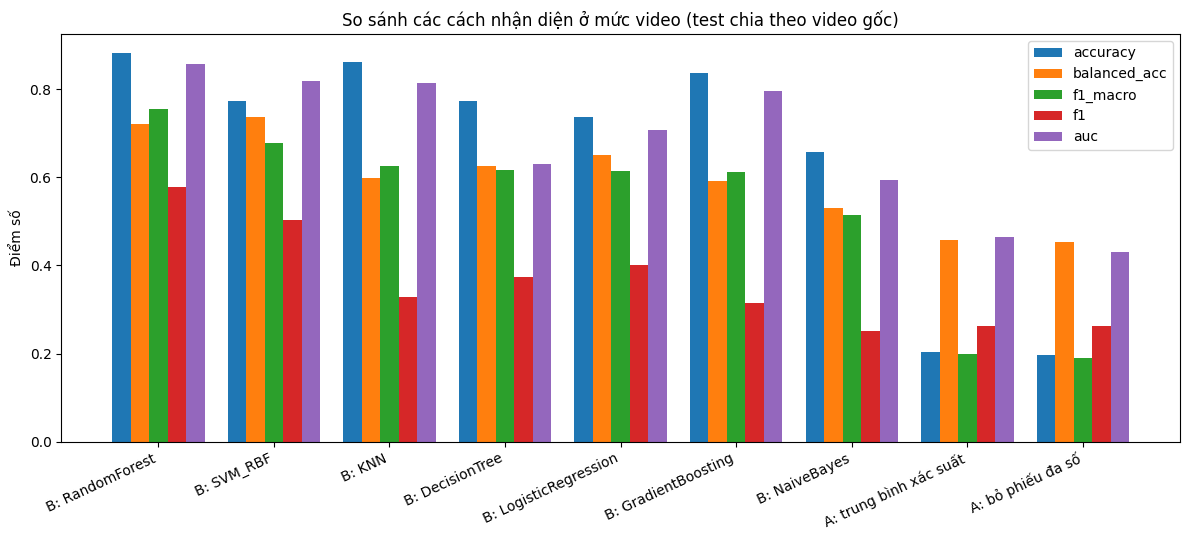

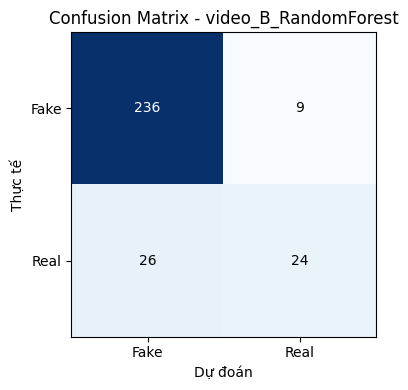


[OK] Đã lưu model video (Cách B) tốt nhất: B: RandomForest -> outputs/best_video_model.pkl


,method,accuracy,balanced_acc,f1_macro,precision,recall,f1,auc
0,B: RandomForest,0.881356,0.721633,0.754640,0.727273,0.48,0.578313,0.857265
1,B: SVM_RBF,0.772881,0.735918,0.678225,0.400000,0.68,0.503704,0.819306
2,B: KNN,0.861017,0.597959,0.625182,0.909091,0.20,0.327869,0.814041
3,B: DecisionTree,0.772881,0.624490,0.617558,0.350877,0.40,0.373832,0.629878
4,B: LogisticRegression,0.735593,0.649796,0.615217,0.325000,0.52,0.400000,0.706367
5,B: GradientBoosting,0.837288,0.591633,0.610989,0.550000,0.22,0.314286,0.796735
6,B: NaiveBayes,0.657627,0.531224,0.514937,0.200000,0.34,0.251852,0.593143
7,A: trung bình xác suất,0.203390,0.456735,0.198082,0.156134,0.84,0.263323,0.464082
8,A: bỏ phiếu đa số,0.196610,0.452653,0.190321,0.154982,0.84,0.261682,0.430408


In [15]:
video_results_df = run_video_training(video_feat_df, OUTPUT_DIR, test_size=0.25)
video_results_df

## 6. Demo nhận diện video

Chạy trên **5 video demo** (không thuộc tập học): **P(Fake) theo từng khung hình**, kết luận Cách A, kết luận Cách B (model video tốt nhất ở bước 5), và so với đáp án thật.

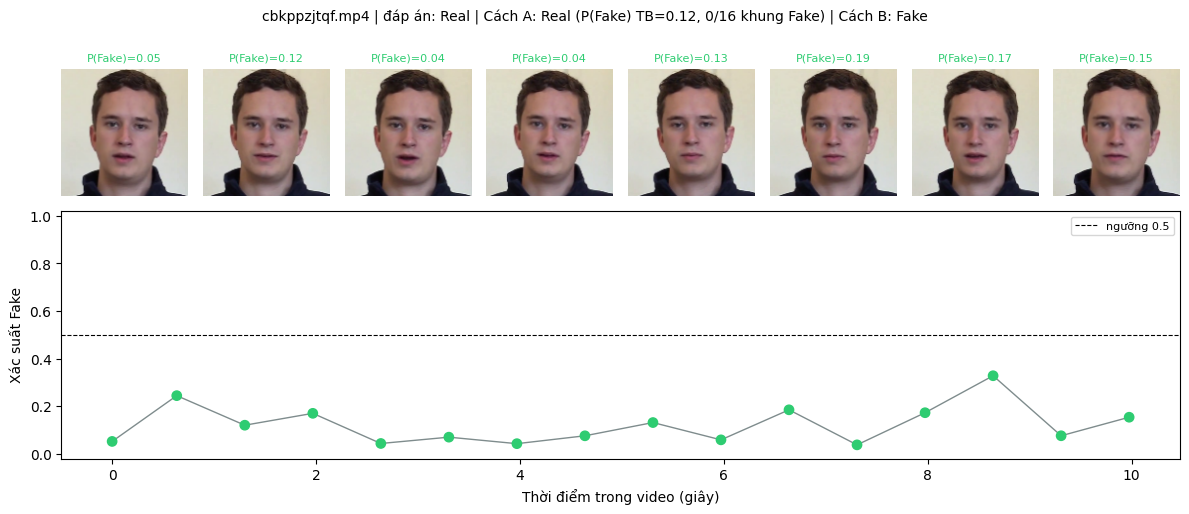

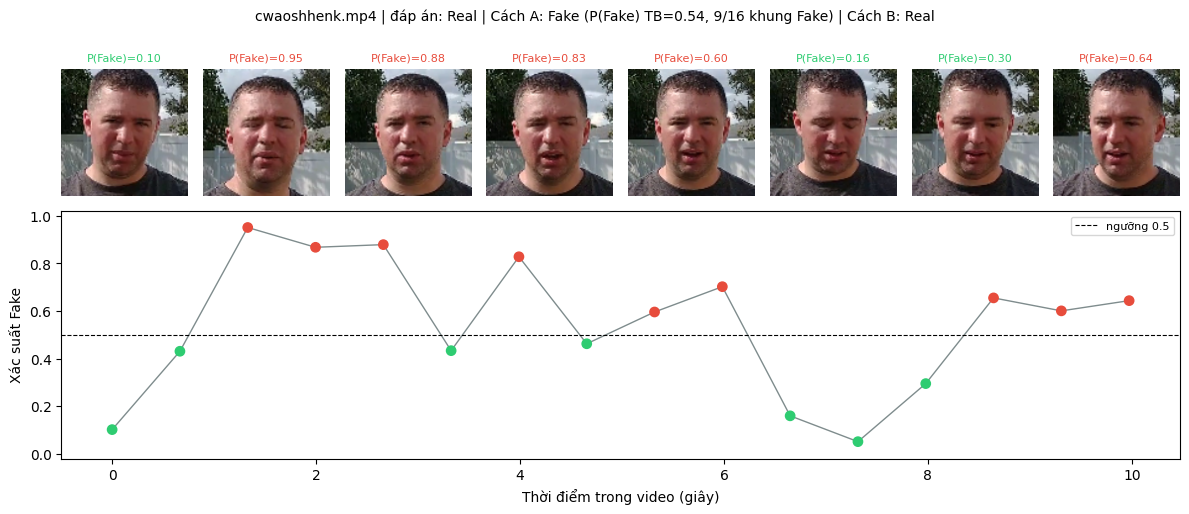

[INSUFFICIENT_QUALITY] tqhthygumd.mp4: mặt quá nhỏ (12) hoặc quá mờ (0) / 16 khung -> không đủ cơ sở kết luận Real/Fake
[NO_FACE] gyeaqcnxhx.mp4: không thấy mặt ở 16/16 khung -> không đủ cơ sở kết luận Real/Fake


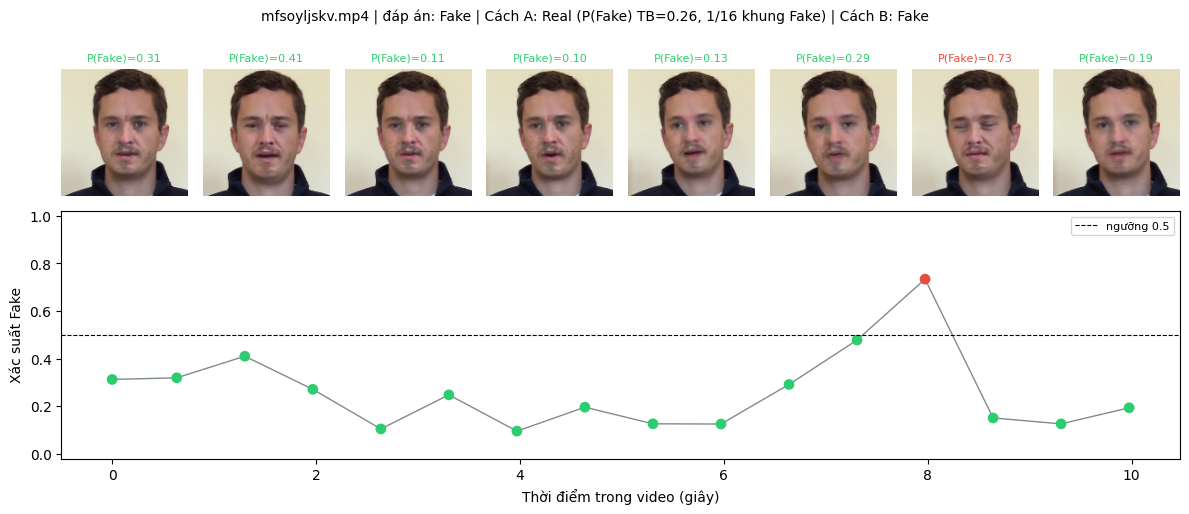

,file,truth,A_pred,A_P(Fake),A_vote,fake_frames,B_pred,B_conf,A_đúng,B_đúng
0,cbkppzjtqf.mp4,Real,Real,0.123,Real,0/16,Fake,0.533,True,False
1,cwaoshhenk.mp4,Real,Fake,0.541,Fake,9/16,Real,0.730,False,True
2,tqhthygumd.mp4,Fake,INSUFFICIENT_QUALITY,NaN,INSUFFICIENT_QUALITY,None,INSUFFICIENT_QUALITY,NaN,False,False
3,gyeaqcnxhx.mp4,Fake,NO_FACE,NaN,NO_FACE,None,NO_FACE,NaN,False,False
4,mfsoyljskv.mp4,Fake,Real,0.262,Real,1/16,Fake,0.927,False,True


In [16]:
def _load_video_model():
    return joblib.load(VIDEO_MODEL_PATH) if os.path.exists(VIDEO_MODEL_PATH) else None


def predict_video(video_path: str, show: bool = True) -> dict:
    """Cách A (luôn có) + Cách B (nếu đã train model video ở bước 5) cho 1 video."""
    info = extract_video(video_path, keep_crops=True)
    name = os.path.basename(video_path)
    if info["status"] != "OK":                       # NO_FACE / INSUFFICIENT_QUALITY: không dự đoán
        truth = demo_truth.get(name) or ({"REAL": "Real", "FAKE": "Fake"}.get(str(meta.get(name, {}).get("label", "")).upper()))
        msg = {"NO_FACE": f"không thấy mặt ở {info['n_no_face']}/{info['n_frames']} khung",
               "INSUFFICIENT_QUALITY": f"mặt quá nhỏ ({info['n_too_small']}) hoặc quá mờ ({info['n_blurry']}) / {info['n_frames']} khung"}[info["status"]]
        if show:
            print(f"[{info['status']}] {name}: {msg} -> không đủ cơ sở kết luận Real/Fake")
        return {"file": name, "truth": truth, "A_pred": info["status"], "A_P(Fake)": None, "A_vote": info["status"],
                "fake_frames": None, "B_pred": info["status"], "B_conf": None}
    p = frame_p_fake(info["feats"])
    agg = aggregate_video_a(p)
    name = os.path.basename(video_path)
    truth = demo_truth.get(name) or ({"REAL": "Real", "FAKE": "Fake"}.get(str(meta.get(name, {}).get("label", "")).upper()))

    out = {"file": name, "truth": truth, "A_pred": agg["pred_mean"], "A_P(Fake)": round(agg["mean_p_fake"], 3),
           "A_vote": agg["pred_vote"], "fake_frames": f"{int((p >= THRESHOLD).sum())}/{len(p)}", "B_pred": None, "B_conf": None}

    bundle_v = _load_video_model()
    if bundle_v is not None:
        Xv = bundle_v["scaler"].transform(video_feature_vector(info["feats"], info["pix_diff"], p).reshape(1, -1))
        pred = int(bundle_v["model"].predict(Xv)[0])
        out["B_pred"] = "Real" if pred == 1 else "Fake"
        if hasattr(bundle_v["model"], "predict_proba"):
            out["B_conf"] = round(float(bundle_v["model"].predict_proba(Xv)[0][pred]), 3)

    if show:
        n_show = min(len(info["crops"]), 8)
        pick = np.linspace(0, len(info["crops"]) - 1, n_show, dtype=int)
        fig = plt.figure(figsize=(12, 5.2))
        gs = fig.add_gridspec(2, n_show, height_ratios=[1, 1.4])
        for k, idx in enumerate(pick):
            ax = fig.add_subplot(gs[0, k])
            ax.imshow(cv2.cvtColor(info["crops"][idx], cv2.COLOR_BGR2RGB))
            ax.set_title(f"P(Fake)={p[idx]:.2f}", fontsize=8, color="#e74c3c" if p[idx] >= THRESHOLD else "#2ecc71")
            ax.axis("off")
        ax = fig.add_subplot(gs[1, :])
        t = np.array(info["frame_ids"]) / info["fps"]
        ax.plot(t, p, color="#7f8c8d", linewidth=1, zorder=1)
        ax.scatter(t, p, c=["#e74c3c" if v >= THRESHOLD else "#2ecc71" for v in p], s=45, zorder=2)
        ax.axhline(THRESHOLD, color="black", linestyle="--", linewidth=0.8, label=f"ngưỡng {THRESHOLD}")
        ax.set_ylim(-0.02, 1.02); ax.set_xlabel("Thời điểm trong video (giây)"); ax.set_ylabel("Xác suất Fake"); ax.legend(loc="upper right", fontsize=8)
        fig.suptitle(f"{name} | đáp án: {truth} | Cách A: {out['A_pred']} (P(Fake) TB={agg['mean_p_fake']:.2f}, {out['fake_frames']} khung Fake)"
                     f" | Cách B: {out['B_pred']}", fontsize=10)
        plt.tight_layout(); plt.show()
    return out


demo_rows = []
for n in demo_files:
    try:
        demo_rows.append(predict_video(os.path.join(DFDC_SRC, n)))
    except Exception as e:
        print(f"[WARN] {n}: {e}")
        demo_rows.append({"file": n, "truth": demo_truth.get(n), "A_pred": "ERROR"})

demo_df = pd.DataFrame(demo_rows)
demo_df["A_đúng"] = demo_df["A_pred"] == demo_df["truth"]
demo_df["B_đúng"] = demo_df["B_pred"] == demo_df["truth"]
demo_df.to_csv(os.path.join(OUTPUT_DIR, "demo_results.csv"), index=False, encoding="utf-8-sig")
demo_df

## Lưu ý khi đọc kết quả

- **Domain gap:** model ảnh học trên ảnh khuôn mặt của dataset ảnh, còn video DFDC bị nén và sinh bằng nhiều kỹ thuật → **Cách A có thể kém hơn nhiều** so với điểm trên ảnh; Cách B (train trực tiếp trên video) thường tốt hơn. Đây là một kết luận đáng đưa vào báo cáo.
- **Lệch lớp:** Fake nhiều hơn Real rất nhiều → nhìn macro-F1 / balanced accuracy / AUC thay vì chỉ accuracy.
- **Đặc trưng thời gian** tính trên các khung cách xa nhau nên chỉ phản ánh độ biến động thô.
- **Video bị loại:** `NO_FACE` / `INSUFFICIENT_QUALITY` không được dự đoán và không vào tập học; xem `video_status.csv` để chỉnh `MIN_FACE_PX`, `BLUR_THRESHOLD`, `MIN_GOOD_FRAMES` nếu loại quá nhiều/ít.
- Haar Cascade có thể cắt sai mặt ở một số video → ảnh hưởng cả hai cách.

## Kết quả sau khi chạy (trong `outputs/`)

- `video_features.csv`, `video_features_vi.csv`, `mo_ta_dac_trung_video.csv` — bảng đặc trưng cấp video (máy đọc / tiếng Việt / từ điển)
- `video_status.csv` — trạng thái từng video (OK / NO_FACE / INSUFFICIENT_QUALITY) + số khung, kích thước mặt, độ mờ
- `video_model_comparison.csv`, `video_comparison.png` — so sánh Cách A và Cách B (7 thuật toán)
- `cm_video_*.png` — confusion matrix của phương pháp tốt nhất
- `best_video_model.pkl` — model ML cấp video tốt nhất (Cách B)
- `demo_results.csv` — kết quả demo 5 video